In [26]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)

from xgboost import XGBClassifier

import matplotlib.pyplot as plt
import seaborn as sns

In [27]:
csv_path = r"C:\Users\ayanl\OneDrive\Desktop\MTech-Project\OSCC_Radiomics.csv"

df = pd.read_csv(csv_path)

print(df.shape)
df.head()

(2590, 477)


,original_shape2D_Elongation,original_shape2D_MajorAxisLength,original_shape2D_MaximumDiameter,original_shape2D_MeshSurface,original_shape2D_MinorAxisLength,original_shape2D_Perimeter,original_shape2D_PerimeterSurfaceRatio,original_shape2D_PixelSurface,original_shape2D_Sphericity,original_firstorder_10Percentile,...,wavelet-LL_gldm_SmallDependenceHighGrayLevelEmphasis,wavelet-LL_gldm_SmallDependenceLowGrayLevelEmphasis,wavelet-LL_ngtdm_Busyness,wavelet-LL_ngtdm_Coarseness,wavelet-LL_ngtdm_Complexity,wavelet-LL_ngtdm_Contrast,wavelet-LL_ngtdm_Strength,Split,Label,Image
0,0.786569,269.110964,307.043971,41499.5,211.674248,1287.019336,0.031013,41499.0,0.561101,89.0,...,14.881234,0.002353,10.767058,0.000568,64.369806,0.028926,0.062876,train,Normal,aug_0_2142.jpg
1,0.719226,273.057722,305.679571,38929.0,196.390161,1473.102597,0.037841,38928.0,0.474798,92.0,...,16.357421,0.002439,10.711671,0.000519,72.512265,0.027686,0.058908,train,Normal,aug_0_4847.jpg
2,0.747779,276.493216,313.968151,42068.0,206.755790,1437.989899,0.034183,42070.0,0.505621,91.0,...,14.205930,0.002097,10.921176,0.000538,63.507449,0.025210,0.062389,train,Normal,aug_0_5167.jpg
3,0.900483,263.629917,316.077522,46583.0,237.394286,1362.391919,0.029247,46582.0,0.561586,92.0,...,13.678103,0.002189,11.273007,0.000522,59.629908,0.025134,0.059756,train,Normal,aug_0_5710.jpg
4,0.719226,273.057722,305.679571,38929.0,196.390161,1473.102597,0.037841,38928.0,0.474798,92.0,...,16.395067,0.002440,10.666724,0.000521,72.284363,0.027579,0.059088,train,Normal,aug_0_5752.jpg


In [66]:
print(df.columns[:10])

Index(['original_shape2D_Elongation', 'original_shape2D_MajorAxisLength',
       'original_shape2D_MaximumDiameter', 'original_shape2D_MeshSurface',
       'original_shape2D_MinorAxisLength', 'original_shape2D_Perimeter',
       'original_shape2D_PerimeterSurfaceRatio',
       'original_shape2D_PixelSurface', 'original_shape2D_Sphericity',
       'original_firstorder_10Percentile'],
      dtype='object')


In [28]:
print(df.isnull().sum())

original_shape2D_Elongation         0
original_shape2D_MajorAxisLength    0
original_shape2D_MaximumDiameter    0
original_shape2D_MeshSurface        0
original_shape2D_MinorAxisLength    0
                                   ..
wavelet-LL_ngtdm_Contrast           0
wavelet-LL_ngtdm_Strength           0
Split                               0
Label                               0
Image                               0
Length: 477, dtype: int64


In [29]:
encoder = LabelEncoder()

df["Label"] = encoder.fit_transform(df["Label"])

print(encoder.classes_)

['Normal' 'OSCC']


In [30]:
train_df = df[df["Split"] == "train"].copy()

val_df = df[df["Split"] == "val"].copy()

print(train_df.shape)
print(val_df.shape)

(2470, 477)
(120, 477)


In [70]:
print(df.columns[:10])
print(train_df.columns[:10])
print(val_df.columns[:10])

Index(['original_shape2D_Elongation', 'original_shape2D_MajorAxisLength',
       'original_shape2D_MaximumDiameter', 'original_shape2D_MeshSurface',
       'original_shape2D_MinorAxisLength', 'original_shape2D_Perimeter',
       'original_shape2D_PerimeterSurfaceRatio',
       'original_shape2D_PixelSurface', 'original_shape2D_Sphericity',
       'original_firstorder_10Percentile'],
      dtype='object')
Index(['original_shape2D_Elongation', 'original_shape2D_MajorAxisLength',
       'original_shape2D_MaximumDiameter', 'original_shape2D_MeshSurface',
       'original_shape2D_MinorAxisLength', 'original_shape2D_Perimeter',
       'original_shape2D_PerimeterSurfaceRatio',
       'original_shape2D_PixelSurface', 'original_shape2D_Sphericity',
       'original_firstorder_10Percentile'],
      dtype='object')
Index(['original_shape2D_Elongation', 'original_shape2D_MajorAxisLength',
       'original_shape2D_MaximumDiameter', 'original_shape2D_MeshSurface',
       'original_shape2D_MinorAxisL

In [71]:
feature_columns = [
    col for col in df.columns
    if col not in ["Image", "Split", "Label"]
]

X_train = train_df[feature_columns]

y_train = train_df["Label"]

X_val = val_df[feature_columns]

y_val = val_df["Label"]

In [72]:
print(feature_columns[:10])

['original_shape2D_Elongation', 'original_shape2D_MajorAxisLength', 'original_shape2D_MaximumDiameter', 'original_shape2D_MeshSurface', 'original_shape2D_MinorAxisLength', 'original_shape2D_Perimeter', 'original_shape2D_PerimeterSurfaceRatio', 'original_shape2D_PixelSurface', 'original_shape2D_Sphericity', 'original_firstorder_10Percentile']


In [73]:
print(type(X_train))
print(X_train.columns[:10])

<class 'pandas.core.frame.DataFrame'>
Index(['original_shape2D_Elongation', 'original_shape2D_MajorAxisLength',
       'original_shape2D_MaximumDiameter', 'original_shape2D_MeshSurface',
       'original_shape2D_MinorAxisLength', 'original_shape2D_Perimeter',
       'original_shape2D_PerimeterSurfaceRatio',
       'original_shape2D_PixelSurface', 'original_shape2D_Sphericity',
       'original_firstorder_10Percentile'],
      dtype='object')


In [74]:
print(X_train.columns[:10])

Index(['original_shape2D_Elongation', 'original_shape2D_MajorAxisLength',
       'original_shape2D_MaximumDiameter', 'original_shape2D_MeshSurface',
       'original_shape2D_MinorAxisLength', 'original_shape2D_Perimeter',
       'original_shape2D_PerimeterSurfaceRatio',
       'original_shape2D_PixelSurface', 'original_shape2D_Sphericity',
       'original_firstorder_10Percentile'],
      dtype='object')


In [75]:
print(X_train.shape)
print(X_val.shape)

(2470, 474)
(120, 474)


In [76]:
print(X_train)

      original_shape2D_Elongation  original_shape2D_MajorAxisLength  \
0                        0.786569                        269.110964   
1                        0.719226                        273.057722   
2                        0.747779                        276.493216   
3                        0.900483                        263.629917   
4                        0.719226                        273.057722   
...                           ...                               ...   
2465                     0.987292                        258.534741   
2466                     0.849936                        260.893730   
2467                     0.958158                        255.142678   
2468                     0.829545                        269.286663   
2469                     0.675098                        249.854826   

      original_shape2D_MaximumDiameter  original_shape2D_MeshSurface  \
0                           307.043971                       41499.5   
1  

### Remove Low Variance Features

In [77]:
from sklearn.feature_selection import VarianceThreshold

selector = VarianceThreshold(threshold=0.01)

X_train = pd.DataFrame(
    selector.fit_transform(X_train),
    columns=X_train.columns[selector.get_support()]
)

X_val = pd.DataFrame(
    selector.transform(X_val),
    columns=X_train.columns
)

print("Training Shape :", X_train.shape)
print("Validation Shape :", X_val.shape)

Training Shape : (2470, 317)
Validation Shape : (120, 317)


### Remove Highly Correlated Features

In [78]:
corr_matrix = X_train.corr().abs()

upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

to_drop = [
    column
    for column in upper.columns
    if any(upper[column] > 0.95)
]

print("Features Removed :", len(to_drop))

X_train = X_train.drop(columns=to_drop)
X_val = X_val.drop(columns=to_drop)

print("Training Shape :", X_train.shape)
print("Validation Shape :", X_val.shape)

Features Removed : 164
Training Shape : (2470, 153)
Validation Shape : (120, 153)


### Standardize Features

In [79]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns
)

X_val = pd.DataFrame(
    scaler.transform(X_val),
    columns=X_train.columns
)

print("Feature Scaling Completed")

Feature Scaling Completed


### Feature Selection

In [80]:
# Save original feature names BEFORE feature selection
original_feature_names = X_train.columns

selector = SelectKBest(
    score_func=mutual_info_classif,
    k=100
)

X_train_selected = selector.fit_transform(X_train, y_train)
X_val_selected = selector.transform(X_val)

selected_feature_names = original_feature_names[selector.get_support()]
print(selected_feature_names)

Index(['original_shape2D_MajorAxisLength', 'original_shape2D_MinorAxisLength',
       'original_shape2D_Perimeter', 'original_shape2D_Sphericity',
       'original_firstorder_90Percentile', 'original_firstorder_Energy',
       'original_firstorder_Entropy', 'original_firstorder_Mean',
       'original_firstorder_Skewness', 'original_glcm_Autocorrelation',
       'original_glcm_ClusterShade', 'original_glcm_Contrast',
       'original_glcm_Correlation', 'original_glcm_Imc1',
       'original_glcm_JointEntropy', 'original_glrlm_GrayLevelNonUniformity',
       'original_glrlm_GrayLevelVariance',
       'original_glrlm_HighGrayLevelRunEmphasis', 'original_glrlm_RunEntropy',
       'original_glrlm_RunLengthNonUniformity',
       'original_glrlm_ShortRunHighGrayLevelEmphasis',
       'original_glszm_GrayLevelVariance',
       'original_glszm_HighGrayLevelZoneEmphasis',
       'original_glszm_LargeAreaEmphasis',
       'original_glszm_LargeAreaHighGrayLevelEmphasis',
       'original_glszm_La

In [81]:
X_train = pd.DataFrame(
    X_train_selected,
    columns=selected_feature_names
)

X_val = pd.DataFrame(
    X_val_selected,
    columns=selected_feature_names
)

In [82]:
import os
import joblib

os.makedirs("saved_models", exist_ok=True)

In [83]:
import joblib

joblib.dump(
    selector,
    "saved_models/selector.pkl"
)

['saved_models/selector.pkl']

In [84]:
joblib.dump(
    list(X_train.columns),
    "saved_models/feature_names.pkl"
)

print("Feature names saved successfully!")

Feature names saved successfully!


In [85]:
feature_names = joblib.load("saved_models/feature_names.pkl")

print(feature_names[:10])

['original_shape2D_MajorAxisLength', 'original_shape2D_MinorAxisLength', 'original_shape2D_Perimeter', 'original_shape2D_Sphericity', 'original_firstorder_90Percentile', 'original_firstorder_Energy', 'original_firstorder_Entropy', 'original_firstorder_Mean', 'original_firstorder_Skewness', 'original_glcm_Autocorrelation']


### Hyperparameter Optimization

In [86]:
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBClassifier

param_grid = {

    "n_estimators": [200,300,400,500,700],

    "max_depth": [3,4,5,6,7],

    "learning_rate": [0.01,0.03,0.05,0.1],

    "subsample": [0.7,0.8,0.9,1.0],

    "colsample_bytree": [0.6,0.7,0.8,0.9,1.0],

    "gamma": [0,0.1,0.2,0.3],

    "min_child_weight": [1,3,5,7],

    "reg_alpha": [0,0.1,0.5,1],

    "reg_lambda": [1,2,3,5]

}

xgb = XGBClassifier(

    objective="binary:logistic",

    eval_metric="logloss",

    random_state=42

)

search = RandomizedSearchCV(

    estimator=xgb,

    param_distributions=param_grid,

    n_iter=30,

    scoring="accuracy",

    cv=5,

    verbose=2,

    random_state=42,

    n_jobs=1

)

search.fit(
    X_train,
    y_train
)

print()

print("Best Parameters")

print(search.best_params_)

print()

print("Best CV Accuracy")

print(search.best_score_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
[CV] END colsample_bytree=0.7, gamma=0, learning_rate=0.1, max_depth=3, min_child_weight=3, n_estimators=200, reg_alpha=0.5, reg_lambda=2, subsample=0.9; total time=   0.3s
[CV] END colsample_bytree=0.7, gamma=0, learning_rate=0.1, max_depth=3, min_child_weight=3, n_estimators=200, reg_alpha=0.5, reg_lambda=2, subsample=0.9; total time=   0.3s
[CV] END colsample_bytree=0.7, gamma=0, learning_rate=0.1, max_depth=3, min_child_weight=3, n_estimators=200, reg_alpha=0.5, reg_lambda=2, subsample=0.9; total time=   0.3s
[CV] END colsample_bytree=0.7, gamma=0, learning_rate=0.1, max_depth=3, min_child_weight=3, n_estimators=200, reg_alpha=0.5, reg_lambda=2, subsample=0.9; total time=   0.3s
[CV] END colsample_bytree=0.7, gamma=0, learning_rate=0.1, max_depth=3, min_child_weight=3, n_estimators=200, reg_alpha=0.5, reg_lambda=2, subsample=0.9; total time=   0.3s
[CV] END colsample_bytree=0.7, gamma=0.1, learning_rate=0.05, max_depth=7

[CV] END colsample_bytree=0.7, gamma=0.1, learning_rate=0.03, max_depth=5, min_child_weight=3, n_estimators=200, reg_alpha=1, reg_lambda=3, subsample=0.8; total time=   0.6s
[CV] END colsample_bytree=0.7, gamma=0.1, learning_rate=0.03, max_depth=5, min_child_weight=3, n_estimators=200, reg_alpha=1, reg_lambda=3, subsample=0.8; total time=   0.7s
[CV] END colsample_bytree=0.7, gamma=0.1, learning_rate=0.03, max_depth=5, min_child_weight=3, n_estimators=200, reg_alpha=1, reg_lambda=3, subsample=0.8; total time=   0.7s
[CV] END colsample_bytree=1.0, gamma=0.2, learning_rate=0.05, max_depth=4, min_child_weight=5, n_estimators=300, reg_alpha=0.1, reg_lambda=1, subsample=0.9; total time=   0.8s
[CV] END colsample_bytree=1.0, gamma=0.2, learning_rate=0.05, max_depth=4, min_child_weight=5, n_estimators=300, reg_alpha=0.1, reg_lambda=1, subsample=0.9; total time=   0.7s
[CV] END colsample_bytree=1.0, gamma=0.2, learning_rate=0.05, max_depth=4, min_child_weight=5, n_estimators=300, reg_alpha=0.1

[CV] END colsample_bytree=0.6, gamma=0.1, learning_rate=0.05, max_depth=5, min_child_weight=1, n_estimators=400, reg_alpha=0, reg_lambda=1, subsample=0.9; total time=   1.4s
[CV] END colsample_bytree=0.9, gamma=0, learning_rate=0.1, max_depth=5, min_child_weight=3, n_estimators=300, reg_alpha=0.1, reg_lambda=2, subsample=0.8; total time=   1.0s
[CV] END colsample_bytree=0.9, gamma=0, learning_rate=0.1, max_depth=5, min_child_weight=3, n_estimators=300, reg_alpha=0.1, reg_lambda=2, subsample=0.8; total time=   1.0s
[CV] END colsample_bytree=0.9, gamma=0, learning_rate=0.1, max_depth=5, min_child_weight=3, n_estimators=300, reg_alpha=0.1, reg_lambda=2, subsample=0.8; total time=   1.0s
[CV] END colsample_bytree=0.9, gamma=0, learning_rate=0.1, max_depth=5, min_child_weight=3, n_estimators=300, reg_alpha=0.1, reg_lambda=2, subsample=0.8; total time=   0.9s
[CV] END colsample_bytree=0.9, gamma=0, learning_rate=0.1, max_depth=5, min_child_weight=3, n_estimators=300, reg_alpha=0.1, reg_lambd

[CV] END colsample_bytree=0.7, gamma=0, learning_rate=0.01, max_depth=3, min_child_weight=5, n_estimators=700, reg_alpha=1, reg_lambda=3, subsample=1.0; total time=   1.4s
[CV] END colsample_bytree=0.7, gamma=0, learning_rate=0.01, max_depth=3, min_child_weight=5, n_estimators=700, reg_alpha=1, reg_lambda=3, subsample=1.0; total time=   1.4s
[CV] END colsample_bytree=0.7, gamma=0, learning_rate=0.01, max_depth=3, min_child_weight=5, n_estimators=700, reg_alpha=1, reg_lambda=3, subsample=1.0; total time=   1.4s
[CV] END colsample_bytree=0.8, gamma=0.1, learning_rate=0.01, max_depth=7, min_child_weight=1, n_estimators=700, reg_alpha=0.1, reg_lambda=2, subsample=0.7; total time=   5.0s
[CV] END colsample_bytree=0.8, gamma=0.1, learning_rate=0.01, max_depth=7, min_child_weight=1, n_estimators=700, reg_alpha=0.1, reg_lambda=2, subsample=0.7; total time=   5.0s
[CV] END colsample_bytree=0.8, gamma=0.1, learning_rate=0.01, max_depth=7, min_child_weight=1, n_estimators=700, reg_alpha=0.1, reg_

In [87]:
model = search.best_estimator_

model.fit(
    X_train,
    y_train
)

print("Training Completed Successfully")

joblib.dump(
    model,
    "saved_models/xgboost_model.pkl"
)

print("✅ XGBoost model saved successfully!")

Training Completed Successfully
✅ XGBoost model saved successfully!


In [56]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Prediction
y_pred = model.predict(X_val)

# Probability prediction
y_prob = model.predict_proba(X_val)[:,1]

# Metrics
accuracy = accuracy_score(y_val, y_pred)

precision = precision_score(y_val, y_pred)

recall = recall_score(y_val, y_pred)

f1 = f1_score(y_val, y_pred)

auc = roc_auc_score(y_val, y_prob)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"AUC Score : {auc:.4f}")

print("\nClassification Report\n")

print(classification_report(y_val, y_pred))

Accuracy  : 0.6583
Precision : 0.7865
Recall    : 0.7609
F1 Score  : 0.7735
AUC Score : 0.5520

Classification Report

              precision    recall  f1-score   support

           0       0.29      0.32      0.31        28
           1       0.79      0.76      0.77        92

    accuracy                           0.66       120
   macro avg       0.54      0.54      0.54       120
weighted avg       0.67      0.66      0.66       120



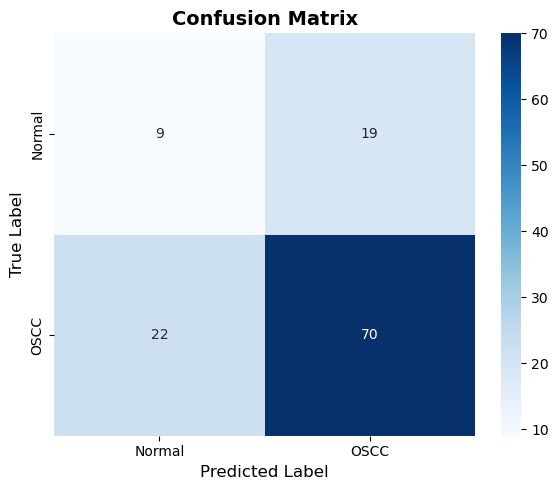

In [43]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_val, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=["Normal","OSCC"],
    yticklabels=["Normal","OSCC"]
)

plt.xlabel("Predicted Label",fontsize=12)

plt.ylabel("True Label",fontsize=12)

plt.title("Confusion Matrix",fontsize=14,fontweight="bold")

plt.tight_layout()

plt.show()

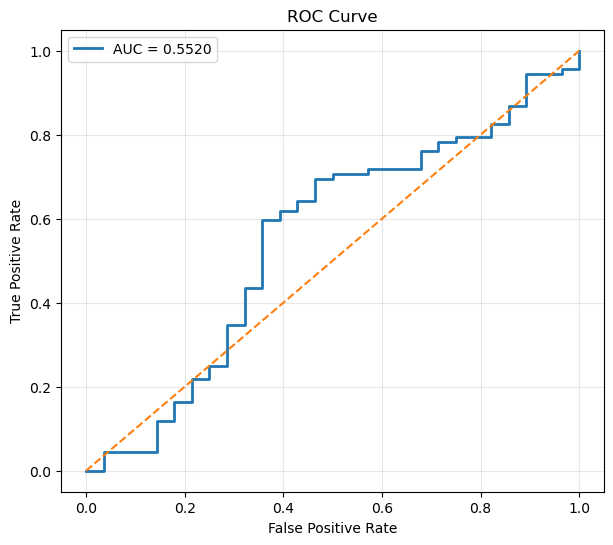

In [44]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(
    y_val,
    y_prob
)

plt.figure(figsize=(7,6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"AUC = {auc:.4f}"
)

plt.plot(
    [0,1],
    [0,1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()

plt.grid(alpha=0.3)

plt.show()

In [45]:
importance = model.feature_importances_

feature_names = X_train.columns

importance_df = pd.DataFrame({

    "Feature":feature_names,

    "Importance":importance

})

importance_df = importance_df.sort_values(

    by="Importance",

    ascending=False

)

print(importance_df.head(20))

    Feature  Importance
73       73    0.079179
17       17    0.073791
21       21    0.038934
94       94    0.030023
90       90    0.027755
16       16    0.022031
40       40    0.021711
28       28    0.019877
19       19    0.015976
54       54    0.014666
75       75    0.014401
26       26    0.014135
85       85    0.013684
64       64    0.013560
15       15    0.013473
91       91    0.012938
65       65    0.012406
49       49    0.012387
57       57    0.011471
43       43    0.011319


In [46]:
import shap
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_val)

ModuleNotFoundError: No module named 'shap'

In [ ]:
sample = 0

shap.plots.waterfall(

    explainer(X_val.iloc[[sample]])[0]

)